In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
import xgboost as xgb
import shap
import os

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load dataset from the local Excel file available in the workspace
file_path = "/content/Telco_customer_churn.xlsx"

try:
    print(f"Loading dataset from {file_path}...")
    df = pd.read_excel(file_path)
    print("Dataset successfully loaded from local Excel file!")
except Exception as e:
    print(f"Could not load from local file due to: {e}. Attempting alternative online repository...")
    fallback_url = "https://raw.githubusercontent.com/datasets/customer-churn/master/data/customer-churn.csv"
    df = pd.read_csv(fallback_url)
    print("Dataset successfully loaded from fallback URL!")

# Print basic information
print(f"\nDataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nFirst 5 Rows of the Dataset:")
display(df.head())

print("\nDataset Information and Column Data Types:")
df.info()

Loading dataset from /content/Telco_customer_churn.xlsx...
Dataset successfully loaded from local Excel file!

Dataset Shape: 7043 rows, 33 columns

First 5 Rows of the Dataset:


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices



Dataset Information and Column Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-

In [3]:
print("Cleaning 'Total Charges' column...")
# Convert Total Charges to numeric, coercing spaces or other errors to NaN
df['Total Charges'] = pd.to_numeric(df['Total Charges'].astype(str).str.strip(), errors='coerce')

# Count missing values
missing_total_charges = df['Total Charges'].isnull().sum()
print(f"Number of missing/empty values in 'Total Charges': {missing_total_charges}")

# Since missing values typically happen for tenure = 0, we can fill with 0
df['Total Charges'] = df['Total Charges'].fillna(0.0)
print("Filled missing values in 'Total Charges' with 0.")

# Verify types and display summary stats of key numerical columns
num_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Value']
print("\nSummary statistics of main numerical variables:")
display(df[num_cols].describe())


Cleaning 'Total Charges' column...
Number of missing/empty values in 'Total Charges': 11
Filled missing values in 'Total Charges' with 0.

Summary statistics of main numerical variables:


,Tenure Months,Monthly Charges,Total Charges,Churn Value
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304,0.265370
std,24.559481,30.090047,2266.794470,0.441561
min,0.000000,18.250000,0.000000,0.000000
25%,9.000000,35.500000,398.550000,0.000000
50%,29.000000,70.350000,1394.550000,0.000000
75%,55.000000,89.850000,3786.600000,1.000000
max,72.000000,118.750000,8684.800000,1.000000


**Reasoning**:
Now we will proceed to visualize the distribution of key numerical variables ('Tenure Months', 'Monthly Charges', 'Total Charges') split by the target variable 'Churn Value' as specified in Step 2 of the EDA instructions.



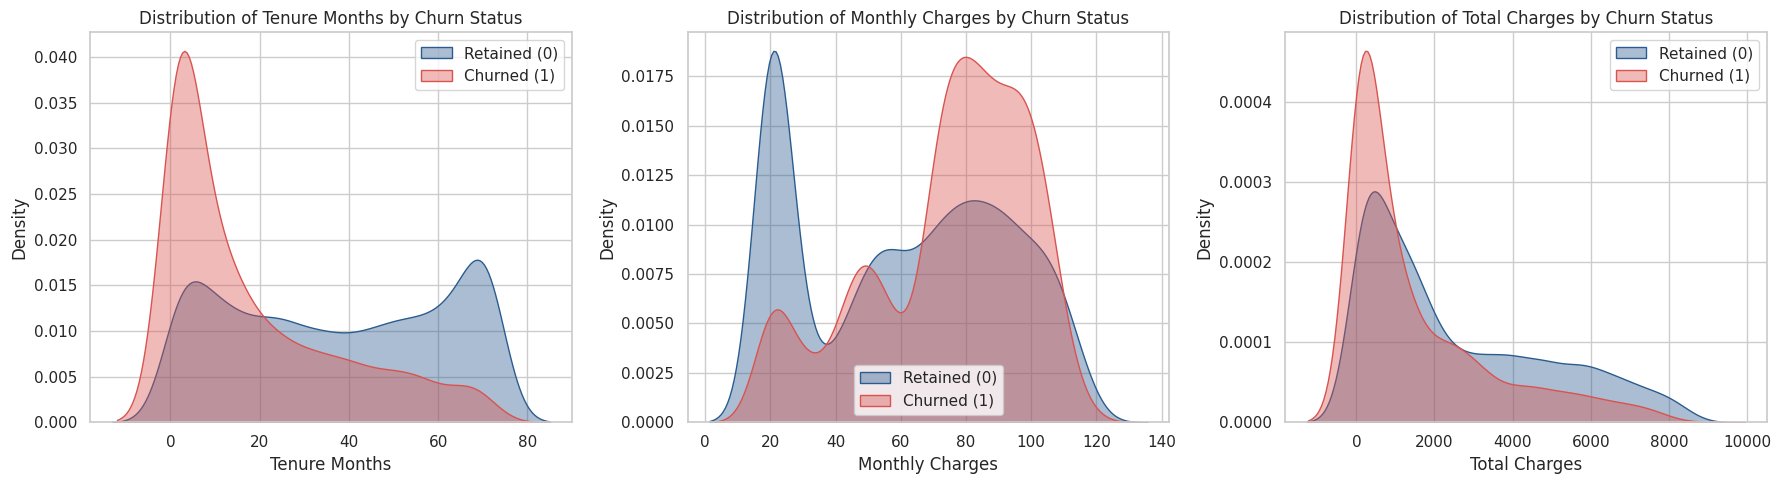

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# List of key numerical columns to plot
num_features = ['Tenure Months', 'Monthly Charges', 'Total Charges']
colors = {0: '#2b5c8f', 1: '#d9534f'}
labels = {0: 'Retained (0)', 1: 'Churned (1)'}

for i, col in enumerate(num_features):
    for churn_val in [0, 1]:
        subset = df[df['Churn Value'] == churn_val]
        sns.kdeplot(
            subset[col],
            fill=True,
            ax=axes[i],
            color=colors[churn_val],
            label=labels[churn_val],
            alpha=0.4
        )
    axes[i].set_title(f'Distribution of {col} by Churn Status', fontsize=12)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')
    axes[i].legend()

plt.tight_layout()
plt.show()

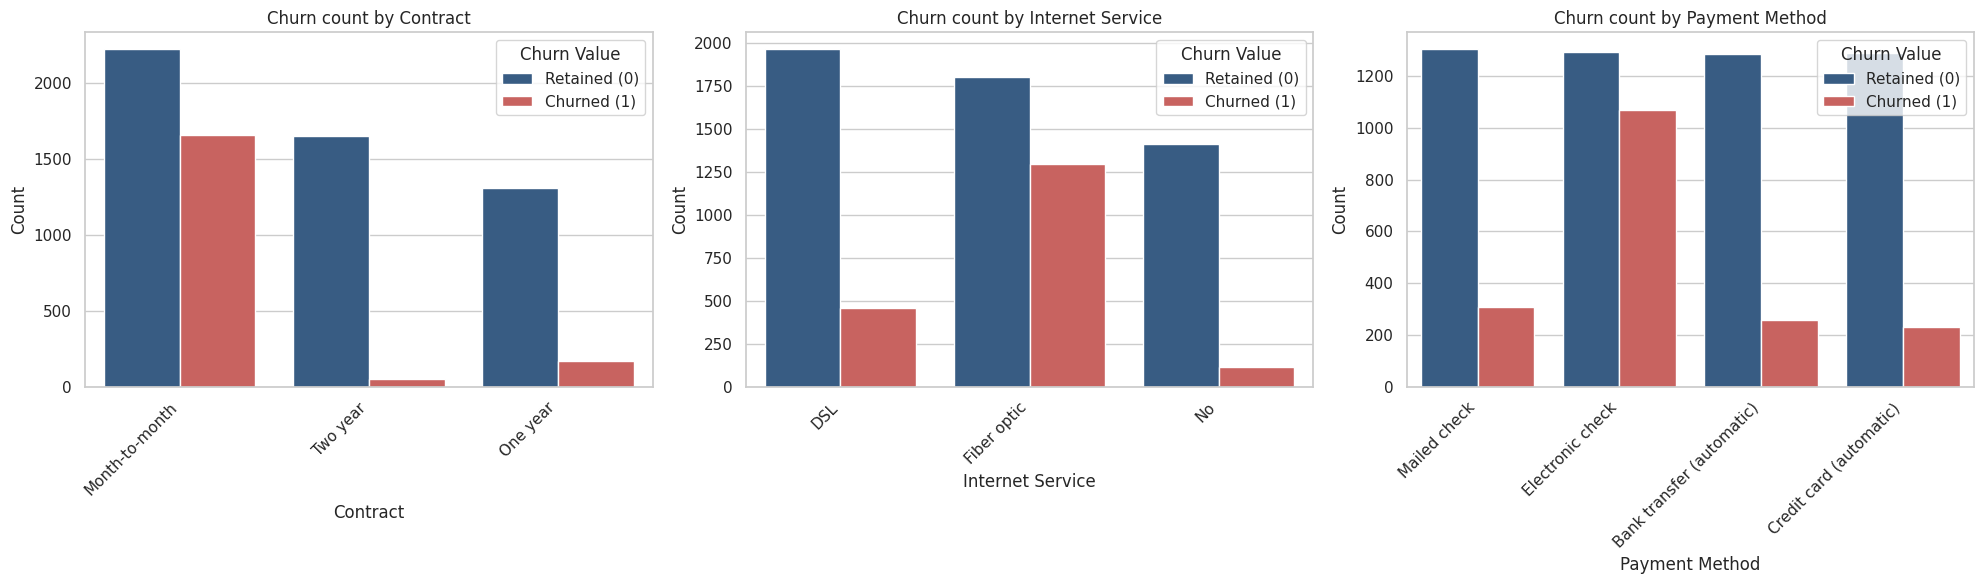

In [6]:
cat_features = ['Contract', 'Internet Service', 'Payment Method']
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(cat_features):
    sns.countplot(
        data=df,
        x=col,
        hue='Churn Value',
        palette={0: '#2b5c8f', 1: '#d9534f'},
        ax=axes[i]
    )
    axes[i].set_title(f'Churn count by {col}', fontsize=12)
    axes[i].set_xticks(range(len(df[col].unique())))
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].legend(title='Churn Value', labels=['Retained (0)', 'Churned (1)'])

plt.tight_layout()
plt.show()

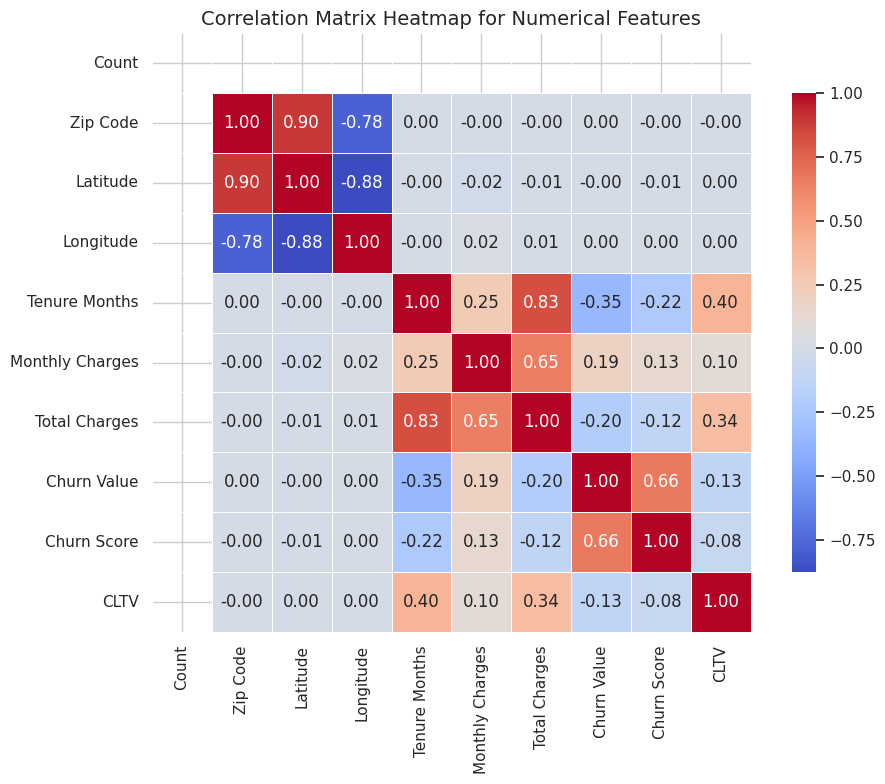

In [7]:
# Select numerical columns for correlation matrix
# We exclude ID-like columns and focus on continuous/discrete features
num_cols_for_corr = ['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Value', 'Churn Score', 'CLTV']
corr_matrix = df[num_cols_for_corr].corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# Draw the heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8}
)

plt.title('Correlation Matrix Heatmap for Numerical Features', fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
# Columns to drop because they are unique identifiers, single-value constants, or direct leakages
cols_to_drop = [
    'CustomerID', 'Count', 'Country', 'State', 'Lat Long',
    'Churn Score', 'Churn Label', 'Churn Reason'
]

# Filter out columns that exist in the dataframe to avoid errors
cols_to_drop = [col for col in cols_to_drop if col in df.columns]

# Separate features and target
X = df.drop(columns=cols_to_drop + ['Churn Value'])
y = df['Churn Value']

print(f"Original features shape: {X.shape}")

# Step 1: Split into temporary training/validation (80%) and final test (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 2: Split temporary training/validation into clean training (80%) and validation (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.20,
    random_state=42,
    stratify=y_temp
)

# Function to display shapes and distributions
def print_split_summary(name, X_split, y_split):
    total = len(y_split)
    counts = y_split.value_counts()
    pcts = y_split.value_counts(normalize=True) * 100
    print(f"\n=== {name} Set ===")
    print(f"Shape: {X_split.shape}")
    for val in [0, 1]:
        count = counts.get(val, 0)
        pct = pcts.get(val, 0.0)
        print(f"  Class {val}: {count} ({pct:.2f}%)")

# Print summaries to verify correctness
print_split_summary("Train", X_train, y_train)
print_split_summary("Validation", X_val, y_val)
print_split_summary("Test", X_test, y_test)


Original features shape: (7043, 24)

=== Train Set ===
Shape: (4507, 24)
  Class 0: 3311 (73.46%)
  Class 1: 1196 (26.54%)

=== Validation Set ===
Shape: (1127, 24)
  Class 0: 828 (73.47%)
  Class 1: 299 (26.53%)

=== Test Set ===
Shape: (1409, 24)
  Class 0: 1035 (73.46%)
  Class 1: 374 (26.54%)


In [9]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
import pandas as pd
import numpy as np

class TelcoFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self):
        # Define binary features, multi-category features, and numerical features
        self.num_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'Total Services', 'Monthly Charges Ratio']
        self.cat_cols = ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
                         'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup',
                         'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies',
                         'Contract', 'Paperless Billing', 'Payment Method', 'Tenure Group']
        self.scaler = StandardScaler()
        self.encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first')

    def fit(self, X, y=None):
        # Engineer features on a copy to determine columns and fit scalers/encoders
        X_engineered = self._engineer_features(X)

        # Fit scaler on engineered numerical columns
        self.scaler.fit(X_engineered[self.num_cols])

        # Fit encoder on engineered categorical columns
        self.encoder.fit(X_engineered[self.cat_cols])

        return self

    def _engineer_features(self, X):
        df_feat = X.copy()

        # 1. Tenure Group: Bin Tenure Months into ranges
        bins = [-1, 12, 24, 48, 60, np.inf]
        labels = ['0-12', '12-24', '24-48', '48-60', '60+']
        df_feat['Tenure Group'] = pd.cut(df_feat['Tenure Months'], bins=bins, labels=labels).astype(str)

        # 2. Total Services: Sum of active services
        # List of service columns to count
        service_cols = ['Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security',
                        'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies']

        # Helper to detect if a service is active (not 'No', not 'No internet service', not 'No phone service')
        def count_active_services(row):
            count = 0
            for col in service_cols:
                if col in row and str(row[col]).strip() in ['Yes', 'Fiber Optic', 'DSL']:
                    count += 1
            return count

        df_feat['Total Services'] = df_feat.apply(count_active_services, axis=1)

        # 3. Monthly Charges Ratio: Monthly Charges / Total Charges (handle division by zero if tenure is 0)
        # If Total Charges is 0, we set the ratio to 0
        df_feat['Monthly Charges Ratio'] = df_feat.apply(
            lambda row: row['Monthly Charges'] / row['Total Charges'] if row['Total Charges'] > 0 else 0.0,
            axis=1
        )

        return df_feat

    def transform(self, X):
        # Apply same feature engineering
        X_engineered = self._engineer_features(X)

        # Scale numerical features
        num_scaled = self.scaler.transform(X_engineered[self.num_cols])
        df_num = pd.DataFrame(num_scaled, columns=self.num_cols, index=X.index)

        # Encode categorical features
        cat_encoded = self.encoder.transform(X_engineered[self.cat_cols])
        encoded_col_names = self.encoder.get_feature_names_out(self.cat_cols)
        df_cat = pd.DataFrame(cat_encoded, columns=encoded_col_names, index=X.index)

        # Combine them together
        X_processed = pd.concat([df_num, df_cat], axis=1)
        return X_processed

# Instantiate and run the pipeline
print("Fitting and transforming datasets with the custom Feature Engineering Pipeline...")
fe_pipeline = TelcoFeatureEngineer()

# Fit ONLY on train split, transform all splits
X_train_proc = fe_pipeline.fit_transform(X_train)
X_val_proc = fe_pipeline.transform(X_val)
X_test_proc = fe_pipeline.transform(X_test)

print(f"\nProcessed Training Shape: {X_train_proc.shape}")
print(f"Processed Validation Shape: {X_val_proc.shape}")
print(f"Processed Test Shape: {X_test_proc.shape}")

print("\nFirst 3 rows of processed training dataset:")
display(X_train_proc.head(3))

Fitting and transforming datasets with the custom Feature Engineering Pipeline...

Processed Training Shape: (4507, 36)
Processed Validation Shape: (1127, 36)
Processed Test Shape: (1409, 36)

First 3 rows of processed training dataset:


,Tenure Months,Monthly Charges,Total Charges,Total Services,Monthly Charges Ratio,Gender_Male,Senior Citizen_Yes,Partner_Yes,Dependents_Yes,Phone Service_Yes,...,Contract_One year,Contract_Two year,Paperless Billing_Yes,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check,Tenure Group_12-24,Tenure Group_24-48,Tenure Group_48-60,Tenure Group_60+
6718,-0.255392,-0.174760,-0.340574,0.130973,-0.423509,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2218,1.610432,1.710993,2.686437,1.974209,-0.513639,1.0,1.0,1.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5867,1.529309,1.652688,2.615961,1.974209,-0.513440,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': xgb.XGBClassifier(random_state=42, eval_metric='logloss')
}

results = []

# Train and evaluate each model
for name, model in models.items():
    # Fit
    model.fit(X_train_proc, y_train)

    # Predict
    y_pred = model.predict(X_val_proc)
    y_proba = model.predict_proba(X_val_proc)[:, 1]

    # Metrics
    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred)
    rec = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    auc = roc_auc_score(y_val, y_proba)

    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

# Display performance summary table
df_results = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)
display(df_results)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
3,Gradient Boosting,0.816327,0.705357,0.528428,0.604207,0.864958
0,Logistic Regression,0.820763,0.704641,0.558528,0.623134,0.863207
2,Random Forest,0.803904,0.672566,0.508361,0.579048,0.843250
4,XGBoost,0.787045,0.608856,0.551839,0.578947,0.841937
1,Decision Tree,0.730257,0.491961,0.511706,0.501639,0.660147


In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd
import numpy as np

# Define 5-fold Stratified Cross-Validation
logging_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Select top 3 models from baseline phase
cv_models = {
    'Logistic Regression': models['Logistic Regression'],
    'Gradient Boosting': models['Gradient Boosting'],
    'XGBoost': models['XGBoost']
}

# Metrics to evaluate
scoring_metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results = []

print("Running 5-Fold Stratified Cross-Validation on training data...")
for name, model in cv_models.items():
    scores = cross_validate(
        model,
        X_train_proc,
        y_train,
        cv=logging_cv,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    result_entry = {'Model': name}
    for metric in scoring_metrics:
        test_key = f'test_{metric}'
        mean_score = np.mean(scores[test_key])
        std_score = np.std(scores[test_key])
        result_entry[f'{metric.capitalize()} Mean'] = mean_score
        result_entry[f'{metric.capitalize()} Std'] = std_score

    cv_results.append(result_entry)

# Format results into a DataFrame and display
df_cv_results = pd.DataFrame(cv_results)
display(df_cv_results.style.format(precision=4))


Running 5-Fold Stratified Cross-Validation on training data...


,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,Roc_auc Mean,Roc_auc Std
0,Logistic Regression,0.8121,0.0111,0.6719,0.0211,0.5703,0.0441,0.6162,0.0313,0.8611,0.0108
1,Gradient Boosting,0.8059,0.0107,0.6653,0.0229,0.5410,0.0431,0.5958,0.0307,0.8566,0.0123
2,XGBoost,0.7837,0.0078,0.6059,0.0126,0.5276,0.0405,0.5634,0.0266,0.8311,0.0122


In [12]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import numpy as np

# Define the cross-validation strategy
tuning_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define hyperparameter search spaces
param_dist_lr = {
    'C': np.logspace(-4, 4, 20),
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

param_dist_gb = {
    'n_estimators': [50, 100, 150, 200, 250],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.6, 0.8, 1.0],
    'min_samples_split': [2, 5, 10]
}

# Initialize classifiers
lr_model = LogisticRegression(random_state=42, max_iter=1000)
gb_model = GradientBoostingClassifier(random_state=42)

# Set up RandomizedSearchCV for Logistic Regression
print("Tuning Logistic Regression...")
lr_search = RandomizedSearchCV(
    estimator=lr_model,
    param_distributions=param_dist_lr,
    n_iter=15,
    scoring='roc_auc',
    cv=tuning_cv,
    random_state=42,
    n_jobs=-1
)
lr_search.fit(X_train_proc, y_train)
best_lr = lr_search.best_estimator_

# Set up RandomizedSearchCV for Gradient Boosting
print("Tuning Gradient Boosting...")
gb_search = RandomizedSearchCV(
    estimator=gb_model,
    param_distributions=param_dist_gb,
    n_iter=15,
    scoring='roc_auc',
    cv=tuning_cv,
    random_state=42,
    n_jobs=-1
)
gb_search.fit(X_train_proc, y_train)
best_gb = gb_search.best_estimator_

print(f"\nBest Logistic Regression Params: {lr_search.best_params_}")
print(f"Best Gradient Boosting Params: {gb_search.best_params_}")

# Evaluate tuned models on the validation set
tuned_models = {
    'Tuned Logistic Regression': best_lr,
    'Tuned Gradient Boosting': best_gb
}

tuned_results = []
for name, model in tuned_models.items():
    y_pred = model.predict(X_val_proc)
    y_proba = model.predict_proba(X_val_proc)[:, 1]

    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred)
    rec = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    auc = roc_auc_score(y_val, y_proba)

    tuned_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

df_tuned_results = pd.DataFrame(tuned_results)
display(df_tuned_results)

Tuning Logistic Regression...
Tuning Gradient Boosting...

Best Logistic Regression Params: {'solver': 'liblinear', 'penalty': 'l1', 'C': np.float64(0.23357214690901212)}
Best Gradient Boosting Params: {'subsample': 0.6, 'n_estimators': 50, 'min_samples_split': 10, 'max_depth': 3, 'learning_rate': 0.1}


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Logistic Regression,0.823425,0.713675,0.558528,0.626642,0.864027
1,Tuned Gradient Boosting,0.812777,0.703704,0.508361,0.590291,0.866273


=== Tuned Logistic Regression threshold optimization ===
Max F1-Score: 0.6677 at Threshold 0.36
Max F2-Score: 0.7558 at Threshold 0.20

=== Tuned Gradient Boosting threshold optimization ===
Max F1-Score: 0.6745 at Threshold 0.40
Max F2-Score: 0.7633 at Threshold 0.13



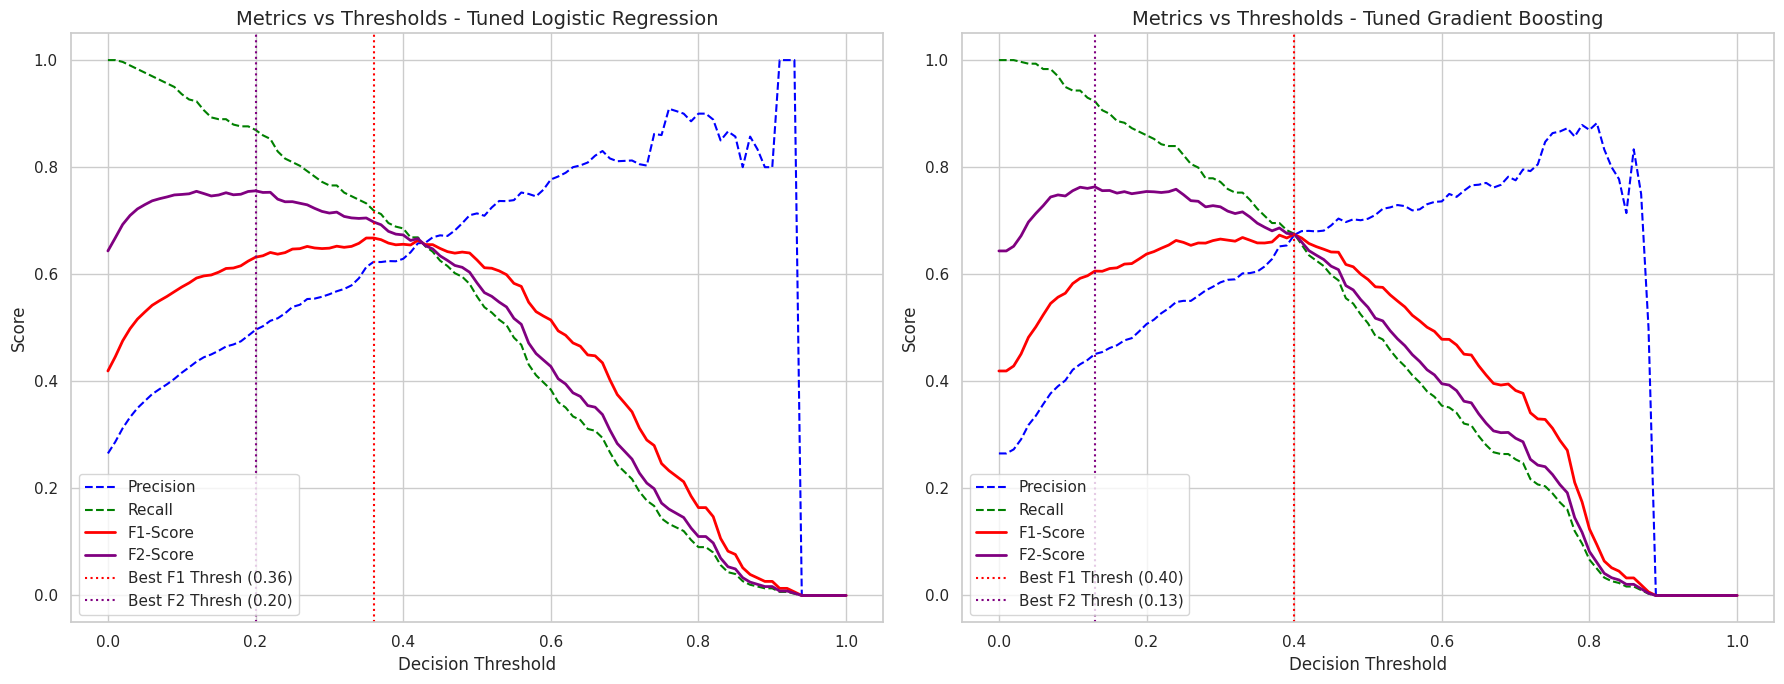

In [13]:
from sklearn.metrics import precision_recall_curve, fbeta_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# We will use the tuned models we saved previously: best_lr and best_gb
models_to_evaluate = {
    'Tuned Logistic Regression': best_lr,
    'Tuned Gradient Boosting': best_gb
}

thresholds = np.arange(0.0, 1.01, 0.01)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for idx, (name, model) in enumerate(models_to_evaluate.items()):
    # Get probability of churn
    y_proba = model.predict_proba(X_val_proc)[:, 1]

    f1_scores = []
    f2_scores = []
    precisions = []
    recalls = []

    for th in thresholds:
        y_pred_th = (y_proba >= th).astype(int)

        # Compute metrics manually for each threshold
        prec = precision_score(y_val, y_pred_th, zero_division=0)
        rec = recall_score(y_val, y_pred_th, zero_division=0)
        f1 = f1_score(y_val, y_pred_th, zero_division=0)
        f2 = fbeta_score(y_val, y_pred_th, beta=2, zero_division=0)

        precisions.append(prec)
        recalls.append(rec)
        f1_scores.append(f1)
        f2_scores.append(f2)

    # Find best thresholds
    best_f1_idx = np.argmax(f1_scores)
    best_f2_idx = np.argmax(f2_scores)

    best_th_f1 = thresholds[best_f1_idx]
    best_val_f1 = f1_scores[best_f1_idx]

    best_th_f2 = thresholds[best_f2_idx]
    best_val_f2 = f2_scores[best_f2_idx]

    print(f"=== {name} threshold optimization ===")
    print(f"Max F1-Score: {best_val_f1:.4f} at Threshold {best_th_f1:.2f}")
    print(f"Max F2-Score: {best_val_f2:.4f} at Threshold {best_th_f2:.2f}\n")

    # Plot curves
    ax = axes[idx]
    ax.plot(thresholds, precisions, label='Precision', color='blue', linestyle='--')
    ax.plot(thresholds, recalls, label='Recall', color='green', linestyle='--')
    ax.plot(thresholds, f1_scores, label='F1-Score', color='red', linewidth=2)
    ax.plot(thresholds, f2_scores, label='F2-Score', color='purple', linewidth=2)

    ax.axvline(best_th_f1, color='red', linestyle=':', label=f'Best F1 Thresh ({best_th_f1:.2f})')
    ax.axvline(best_th_f2, color='purple', linestyle=':', label=f'Best F2 Thresh ({best_th_f2:.2f})')

    ax.set_title(f'Metrics vs Thresholds - {name}', fontsize=14)
    ax.set_xlabel('Decision Threshold')
    ax.set_ylabel('Score')
    ax.legend(loc='lower left')
    ax.grid(True)

plt.tight_layout()
plt.show()

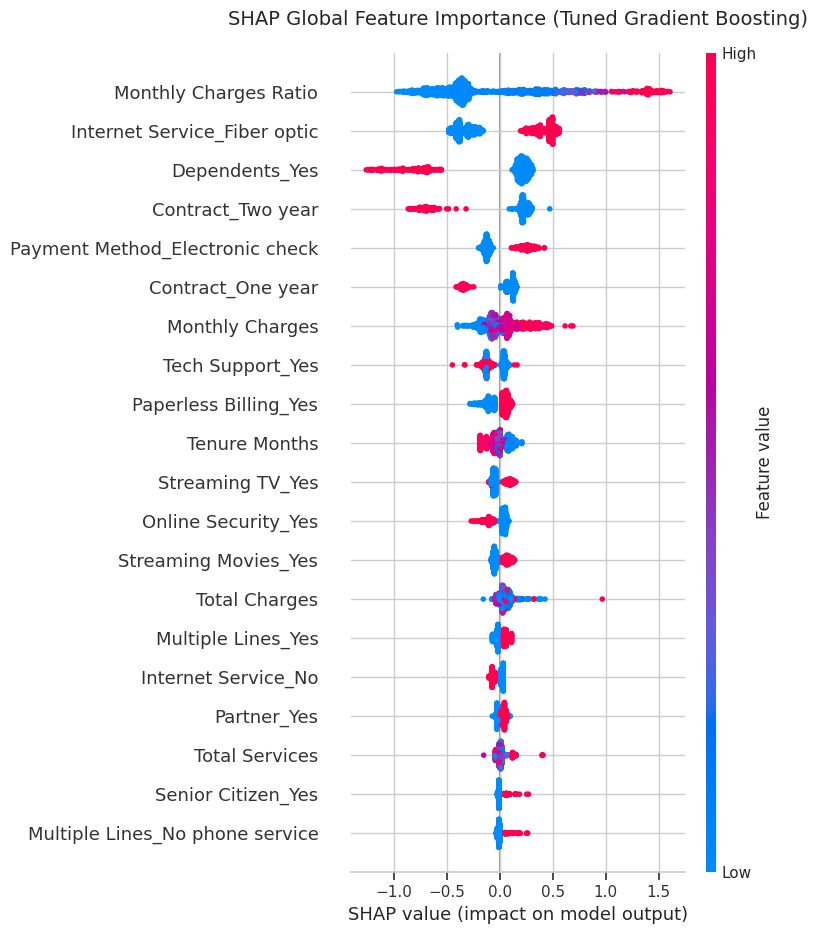


=== Individual SHAP breakdown for high-risk Customer Index 236 (Original Index: 1651) ===
Predicted Churn Probability: 88.9104%


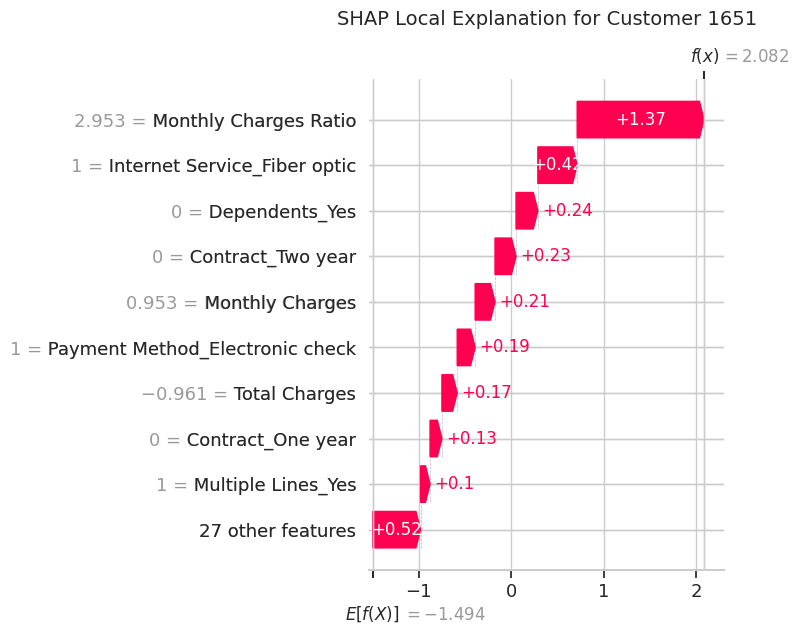

In [14]:
import shap
import matplotlib.pyplot as plt

# Initialize the SHAP explainer on the Tuned Gradient Boosting model
# We use the TreeExplainer as Gradient Boosting is a tree-based ensemble
explainer = shap.TreeExplainer(best_gb)
shap_values = explainer(X_val_proc)

# 1. Global Feature Importance Summary Plot
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_val_proc, show=False)
plt.title("SHAP Global Feature Importance (Tuned Gradient Boosting)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

# 2. Individual Customer Risk Breakdown
# Predict probabilities to find a high-risk customer in the validation set
y_val_proba = best_gb.predict_proba(X_val_proc)[:, 1]
high_risk_indices = [i for i, prob in enumerate(y_val_proba) if prob > 0.85]

if len(high_risk_indices) > 0:
    # Pick the first high-risk customer
    high_risk_idx = high_risk_indices[0]
    customer_id_val = X_val.iloc[high_risk_idx].name # index of original sample
    print(f"\n=== Individual SHAP breakdown for high-risk Customer Index {high_risk_idx} (Original Index: {customer_id_val}) ===")
    print(f"Predicted Churn Probability: {y_val_proba[high_risk_idx]:.4%}")

    # Generate Waterfall plot for this specific customer
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_values[high_risk_idx], show=False)
    plt.title(f"SHAP Local Explanation for Customer {customer_id_val}", fontsize=14, pad=15)
    plt.tight_layout()
    plt.show()
else:
    print("No customer found with a churn probability above 85% in the validation set.")

In [15]:
import pandas as pd
import numpy as np

# 1. Define Risk Segments based on Tuned Gradient Boosting validation probabilities
y_val_proba = best_gb.predict_proba(X_val_proc)[:, 1]

val_retention_df = pd.DataFrame({
    'Churn Probability': y_val_proba,
    'Monthly Charges': X_val['Monthly Charges'],
    'Contract': X_val['Contract'],
    'Tenure Months': X_val['Tenure Months'],
    'Tech Support': X_val['Tech Support'],
    'Internet Service': X_val['Internet Service']
}, index=X_val.index)

def categorize_risk(prob):
    if prob < 0.3:
        return 'Low Risk'
    elif prob < 0.7:
        return 'Medium Risk'
    else:
        return 'High Risk'

val_retention_df['Risk Segment'] = val_retention_df['Churn Probability'].apply(categorize_risk)

# 2. Financial Metrics Calculation
high_risk_customers = val_retention_df[val_retention_df['Risk Segment'] == 'High Risk']
total_rev_at_risk = high_risk_customers['Monthly Charges'].sum()
simulated_savings = total_rev_at_risk * 0.20

print("=== Financial Analysis of Churn Risk (Validation Set) ===")
print(f"Number of High-Risk Customers: {len(high_risk_customers)}")
print(f"Total Monthly Revenue at Risk: ${total_rev_at_risk:,.2f}")
print(f"Estimated Monthly Savings (with 20% Retention Success): ${simulated_savings:,.2f}\n")

# 3. Rule-Based Personalized Retention Recommendation Logic
def get_recommendation(row):
    if row['Contract'] == 'Month-to-month':
        return "Offer long-term contract discount (e.g., 1-Year or 2-Year plan with 15% off)"
    elif row['Internet Service'] != 'No' and row['Tech Support'] == 'No':
        return "Proactive Tech Support setup outreach & free 3-month trial of Premium Support"
    elif row['Tenure Months'] < 12:
        return "First-year loyalty appreciation incentive & check-in call"
    else:
        return "Personalized account review with tailored bundle discount plan"

val_retention_df['Personalized Recommendation'] = val_retention_df.apply(get_recommendation, axis=1)

# 4. Display high-risk validation customers with their specific strategies
high_risk_recommendations = val_retention_df[val_retention_df['Risk Segment'] == 'High Risk'].sort_values(by='Churn Probability', ascending=False)

print("=== Sample High-Risk Customer Profiles and Retention Strategies ===")
display(high_risk_recommendations[['Churn Probability', 'Monthly Charges', 'Contract', 'Risk Segment', 'Personalized Recommendation']].head(10))

=== Financial Analysis of Churn Risk (Validation Set) ===
Number of High-Risk Customers: 98
Total Monthly Revenue at Risk: $8,129.05
Estimated Monthly Savings (with 20% Retention Success): $1,625.81

=== Sample High-Risk Customer Profiles and Retention Strategies ===


,Churn Probability,Monthly Charges,Contract,Risk Segment,Personalized Recommendation
1651,0.889104,93.30,Month-to-month,High Risk,"Offer long-term contract discount (e.g., 1-Yea..."
5906,0.885488,84.60,Month-to-month,High Risk,"Offer long-term contract discount (e.g., 1-Yea..."
578,0.875779,91.30,Month-to-month,High Risk,"Offer long-term contract discount (e.g., 1-Yea..."
449,0.872694,99.75,Month-to-month,High Risk,"Offer long-term contract discount (e.g., 1-Yea..."
1431,0.865236,84.65,Month-to-month,High Risk,"Offer long-term contract discount (e.g., 1-Yea..."
1643,0.861532,98.25,Month-to-month,High Risk,"Offer long-term contract discount (e.g., 1-Yea..."
2676,0.859736,80.55,Month-to-month,High Risk,"Offer long-term contract discount (e.g., 1-Yea..."
263,0.848410,100.60,Month-to-month,High Risk,"Offer long-term contract discount (e.g., 1-Yea..."
1020,0.842977,101.55,Month-to-month,High Risk,"Offer long-term contract discount (e.g., 1-Yea..."
1582,0.839029,94.60,Month-to-month,High Risk,"Offer long-term contract discount (e.g., 1-Yea..."


In [16]:
import joblib
import os

# 1. Serialize the feature engineering pipeline and the best models
print("Saving serialization artifacts to disk...")
joblib.dump(fe_pipeline, 'fe_pipeline.joblib')
joblib.dump(best_gb, 'best_gb.joblib')
joblib.dump(best_lr, 'best_lr.joblib')
print("Artifacts successfully saved: 'fe_pipeline.joblib', 'best_gb.joblib', 'best_lr.joblib'.")

# 2. Write the FastAPI application code to a file named app.py
fastapi_code = """from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
import pandas as pd
import joblib
import uvicorn

app = FastAPI(
    title=\"Telco Churn Prediction & Retention Engine API\",
    description=\"Production API stub for predicting customer churn risk and delivering personalized retention recommendations.\",
    version=\"1.0.0\"
)

# Global variable placeholders for loaded artifacts
fe_pipeline = None
model = None

@app.on_event(\"startup\")
def load_artifacts():
    global fe_pipeline, model
    try:
        fe_pipeline = joblib.load('fe_pipeline.joblib')
        model = joblib.load('best_gb.joblib')  # Defaults to Tuned Gradient Boosting as best model
        print(\"Artifacts successfully loaded on startup!\")
    except Exception as e:
        print(f\"Error loading artifacts: {e}\")

class CustomerInput(BaseModel):
    Gender: str = Field(..., example=\"Female\")
    Senior_Citizen: str = Field(..., alias=\"Senior Citizen\", example=\"No\")
    Partner: str = Field(..., example=\"Yes\")
    Dependents: str = Field(..., example=\"No\")
    Tenure_Months: int = Field(..., alias=\"Tenure Months\", example=1)
    Phone_Service: str = Field(..., alias=\"Phone Service\", example=\"Yes\")
    Multiple_Lines: str = Field(..., alias=\"Multiple Lines\", example=\"No\")
    Internet_Service: str = Field(..., alias=\"Internet Service\", example=\"Fiber Optic\")
    Online_Security: str = Field(..., alias=\"Online Security\", example=\"No\")
    Online_Backup: str = Field(..., alias=\"Online Backup\", example=\"No\")
    Device_Protection: str = Field(..., alias=\"Device Protection\", example=\"No\")
    Tech_Support: str = Field(..., alias=\"Tech Support\", example=\"No\")
    Streaming_TV: str = Field(..., alias=\"Streaming TV\", example=\"No\")
    Streaming_Movies: str = Field(..., alias=\"Streaming Movies\", example=\"No\")
    Contract: str = Field(..., example=\"Month-to-month\")
    Paperless_Billing: str = Field(..., alias=\"Paperless Billing\", example=\"Yes\")
    Payment_Method: str = Field(..., alias=\"Payment Method\", example=\"Electronic check\")
    Monthly_Charges: float = Field(..., alias=\"Monthly Charges\", example=70.05)
    Total_Charges: float = Field(..., alias=\"Total Charges\", example=70.05)

    class Config:
        populate_by_name = True

def get_recommendation_logic(contract, internet_service, tech_support, tenure_months):
    if contract == 'Month-to-month':
        return \"Offer long-term contract discount (e.g., 1-Year or 2-Year plan with 15% off)\"
    elif internet_service != 'No' and tech_support == 'No':
        return \"Proactive Tech Support setup outreach & free 3-month trial of Premium Support\"
    elif tenure_months < 12:
        return \"First-year loyalty appreciation incentive & check-in call\"
    else:
        return \"Personalized account review with tailored bundle discount plan\"

@app.post(\"/predict\")
def predict_churn(customer: CustomerInput):
    if fe_pipeline is None or model is None:
        raise HTTPException(status_code=500, detail=\"Model artifacts not loaded properly.\")

    try:
        # Convert inputs to DataFrame with correct original feature column names
        data_dict = {
            'Gender': [customer.Gender],
            'Senior Citizen': [customer.Senior_Citizen],
            'Partner': [customer.Partner],
            'Dependents': [customer.Dependents],
            'Tenure Months': [customer.Tenure_Months],
            'Phone Service': [customer.Phone_Service],
            'Multiple Lines': [customer.Multiple_Lines],
            'Internet Service': [customer.Internet_Service],
            'Online Security': [customer.Online_Security],
            'Online Backup': [customer.Online_Backup],
            'Device Protection': [customer.Device_Protection],
            'Tech Support': [customer.Tech_Support],
            'Streaming TV': [customer.Streaming_TV],
            'Streaming Movies': [customer.Streaming_Movies],
            'Contract': [customer.Contract],
            'Paperless Billing': [customer.Paperless_Billing],
            'Payment Method': [customer.Payment_Method],
            'Monthly Charges': [customer.Monthly_Charges],
            'Total Charges': [customer.Total_Charges]
        }
        df_input = pd.DataFrame(data_dict)

        # Preprocess input using loaded pipeline
        df_proc = fe_pipeline.transform(df_input)

        # Predict probability
        proba = float(model.predict_proba(df_proc)[0, 1])

        # Segment risk
        if proba < 0.3:
            risk_segment = \"Low Risk\"
        elif proba < 0.7:
            risk_segment = \"Medium Risk\"
        else:
            risk_segment = \"High Risk\"

        # Get recommendation
        rec = get_recommendation_logic(
            customer.Contract,
            customer.Internet_Service,
            customer.Tech_Support,
            customer.Tenure_Months
        )

        return {
            \"churn_probability\": proba,
            \"risk_segment\": risk_segment,
            \"personalized_recommendation\": rec
        }
    except Exception as e:
        raise HTTPException(status_code=400, detail=str(e))

@app.get(\"/\")
def root():
    return {\"message\": \"Welcome to the Telco Churn Prediction API! Please visit /docs for API schema definitions.\"}
"""

with open('app.py', 'w') as f:
    f.write(fastapi_code)

print("FastAPI app.py written to disk successfully!")


Saving serialization artifacts to disk...
Artifacts successfully saved: 'fe_pipeline.joblib', 'best_gb.joblib', 'best_lr.joblib'.
FastAPI app.py written to disk successfully!


In [17]:
from scipy.stats import ks_2samp
import pandas as pd

def detect_drift(reference_df, target_df, features, alpha=0.05):
    print("=== MLOps Drift Detection Report (Kolmogorov-Smirnov Test) ===\n")
    print(f"Reference Set Size: {len(reference_df)}")
    print(f"Target Set Size: {len(target_df)}")
    print(f"Significance Level (Alpha): {alpha}\n")

    drift_results = []
    for feature in features:
        if feature not in reference_df.columns or feature not in target_df.columns:
            print(f"Warning: Feature '{feature}' not found in both dataframes. Skipping.")
            continue

        # Extract distributions
        ref_dist = reference_df[feature]
        tar_dist = target_df[feature]

        # Run KS test
        ks_stat, p_val = ks_2samp(ref_dist, tar_dist)

        # Determine drift status
        drift_detected = p_val < alpha
        status = "DRIFT DETECTED" if drift_detected else "No Drift Detected"

        drift_results.append({
            'Feature': feature,
            'KS Statistic': ks_stat,
            'p-value': p_val,
            'Status': status
        })

        print(f"Feature: {feature:<20} | KS Stat: {ks_stat:.4f} | p-value: {p_val:.4e} | Result: {status}")

    print("\n===========================================================")
    return pd.DataFrame(drift_results)

# Perform drift detection between Training set and Validation set on continuous features
continuous_features = ['Tenure Months', 'Monthly Charges', 'Total Charges']
drift_report_df = detect_drift(X_train, X_val, continuous_features)


=== MLOps Drift Detection Report (Kolmogorov-Smirnov Test) ===

Reference Set Size: 4507
Target Set Size: 1127
Significance Level (Alpha): 0.05

Feature: Tenure Months        | KS Stat: 0.0344 | p-value: 2.2993e-01 | Result: No Drift Detected
Feature: Monthly Charges      | KS Stat: 0.0341 | p-value: 2.3861e-01 | Result: No Drift Detected
Feature: Total Charges        | KS Stat: 0.0404 | p-value: 1.0217e-01 | Result: No Drift Detected



In [18]:
import zipfile
import os
import pandas as pd

# 1. Export CSV reports of the evaluation results
print("Saving evaluation report CSVs...")
drift_report_df.to_csv('drift_report.csv', index=False)

# Construct a simple model metrics dataframe from our previous tuned results
df_tuned_results.to_csv('model_metrics.csv', index=False)
print("CSVs successfully saved: 'drift_report.csv', 'model_metrics.csv'")

# 2. List of files to verify and package
required_files = [
    'app.py',
    'fe_pipeline.joblib',
    'best_gb.joblib',
    'best_lr.joblib',
    'drift_report.csv',
    'model_metrics.csv'
]

# Verify existence of all files
print("\nVerifying file existence:")
missing_files = []
for file in required_files:
    exists = os.path.exists(file)
    print(f"- {file:<20} : {'Found' if exists else 'MISSING'}")
    if not exists:
        missing_files.append(file)

if missing_files:
    print(f"\nWarning: Missing the following files: {missing_files}")
else:
    print("\nAll required files are verified and present. Building zip archive...")

    # 3. Create production handover zip file
    zip_filename = 'production_handover.zip'
    with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for file in required_files:
            zipf.write(file)

    print(f"Successfully created zip archive: '{zip_filename}'")

    # 4. Verify and print the contents of the final zip archive
    print(f"\n=== Contents of '{zip_filename}' ===")
    with zipfile.ZipFile(zip_filename, 'r') as zipf:
        for name in zipf.namelist():
            info = zipf.getinfo(name)
            print(f"File: {name:<20} | Size: {info.file_size:,} bytes")

Saving evaluation report CSVs...
CSVs successfully saved: 'drift_report.csv', 'model_metrics.csv'

Verifying file existence:
- app.py               : Found
- fe_pipeline.joblib   : Found
- best_gb.joblib       : Found
- best_lr.joblib       : Found
- drift_report.csv     : Found
- model_metrics.csv    : Found

All required files are verified and present. Building zip archive...
Successfully created zip archive: 'production_handover.zip'

=== Contents of 'production_handover.zip' ===
File: app.py               | Size: 5,285 bytes
File: fe_pipeline.joblib   | Size: 6,567 bytes
File: best_gb.joblib       | Size: 79,672 bytes
File: best_lr.joblib       | Size: 2,347 bytes
File: drift_report.csv     | Size: 254 bytes
File: model_metrics.csv    | Size: 288 bytes
